<a href="https://colab.research.google.com/github/EduMoura321/Non-linear-systems/blob/main/Flutter_Non_linear_ThinTheory.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
'''
=====================================================================
Nome do programa: Airfoil Pitch and Plunge (Piston Theory)
Data: 10/11/2026
Linguagem: Phyton
Depêndencias: Mathplotlib, Numpy e scipy
--------------------------------------------------------------------
Nome: Eduardo Moura Ventorim
Instituto de Física
UFMS - Campo Grande
Descrição: Programa que realiza a partir de metódos númericos a
solução do dominio temporal da EDO que descreve um aerofolio em regime
aerodinamico simples, e analisa seu comportamente passivo de efeito flutter
===================================================================
'''
#====================================================================
#Bibliotecas utilizadas:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy import signal
from scipy.special import hankel2
import pywt
#=====================================================================

In [8]:
# =====================================================================
# Retirados do artigo (NASA / Referência de Seção Típica Não Linear):
# Link do artigo: https://ntrs.nasa.gov/api/citations/20010030438/downloads/20010030438.pdf
# Parâmetros Físicos do sistema
m = 12.08      # massa (KG)
a = -0.5       # posição adimensional do eixo elástico em relação ao centro da corda
b = 0.135      # semi-corda (m)
U = 25.0       # Velocidade escoamento (m/s) - Variável de estudo de flutter
p = 1.225      # densidade do ar (kg/m^2)
Xab = 0.35     # desbalanceamento estático (massa x distância ao centro de gravidade)
Ig = 0.065     # momento de inércia em relação ao eixo elástico (kg*m^2)
Kh = 2820.0    # Rigidez linear H (plunge) (N/m)
Ka = 50.0      # Rigidez linear alpha (pitch) (N*m/rad)
Kh3 = 0.0      # Rigidez Não linear H (cúbica - dependendo do caso do artigo)
Ka3 = 550.0    # Rigidez Não linear alpha (cúbica - termo de rigidez não linear de pitch)
Ch = 27.0      # Amortecimento Estrutural H (N*s/m)
Ca = 0.07      # Amortecimento Estrutural alpha (N*m*s/rad)
Cl = 6.283     # Coeficiente de sustentação (Teoria do perfil fino: 2*pi)
Cm = 0.0       # Coeficiente de momento (Teoria do perfil fino para o centro aerodinâmico)

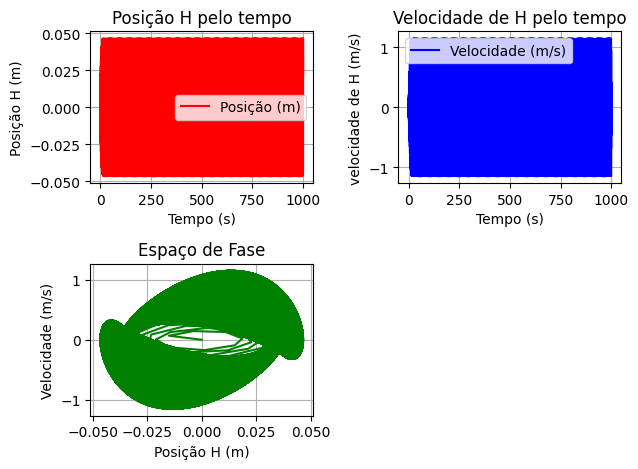

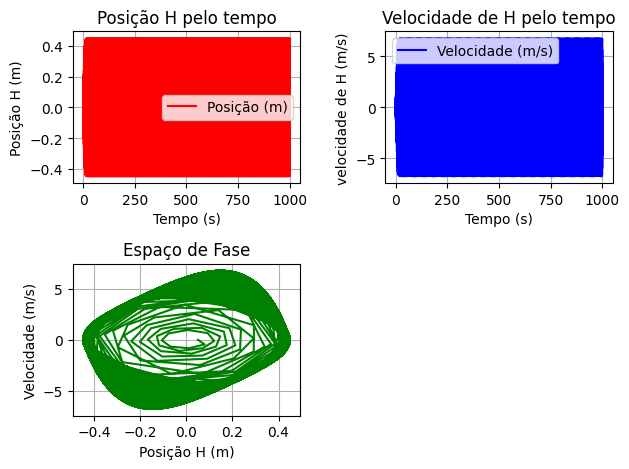

In [11]:
#=====================================================================
#Forças baseado na aerodinamica quasi-estatica  linear
def F_aero(t,th, th_dot, h, h_dot):
#Angulo Effetivo
  ang_eff = th + (h_dot)/U + b*(0.5-a)*(th_dot/U)
#Forças externas Aerodinamicas (modelo Linear e teoria dos perfis finos)
  #lift
  L = p*(U**2)*b*Cl*ang_eff
  #Moment
  M = p*(U**2)*(b**2)*Cm*ang_eff
  F = np.array([-L,
                 M],dtype=float)
  return F
#=====================================================================
#Matrizes De Modelagem EDO
M_mat = np.array([[m, Xab*m],
              [Xab*m, Ig+(m*(Xab**2))]],dtype=float)

K = np.array([[Kh,0],
              [0,Ka]],dtype=float)

K_3 = np.array([[Kh3,0],
                [0,Ka3]],dtype=float)

C_est = np.array([[Ch,0],
                     [0,Ca]],dtype=float)
#======================================================================
#Definir sistema e C.C
def sist(t,X):
  x = X[:2]

  x_dot = X[2:]

  h, th = x
  h_dot, th_dot = x_dot

  x_dotdot = np.linalg.solve(M_mat,F_aero(t,th,th_dot,h,h_dot,)- C_est@x_dot - K@x - K_3@(x**3))
  return np.concatenate((x_dot, x_dotdot))
X0 = np.zeros(4)
X0[0] = 0.0
X0[1] = 0.05
t_eval = np.linspace (0,1000,10000)
#Soluções
sol = solve_ivp(sist,(0,1000),X0, t_eval=t_eval)
#Saídas
t = sol.t
h = sol.y[0]
th = sol.y[1]
h_dot = sol.y[2]
th_dot = sol.y[3]
#========================================================================
#Plots e espaços de fase
#--------------------------------------------------------------
#Gráfico de posíção Altura
plt.figure()
plt.subplot(2,2,1)
plt.plot(t, h, label='Posição (m)', color='red')
plt.legend()
plt.title('Posição H pelo tempo')
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('Posição H (m)')

#gráfico de velocidade
plt.subplot(2,2,2)
plt.plot(t, h_dot, label='Velocidade (m/s)', color='blue')
plt.title('Velocidade de H pelo tempo')
plt.legend()
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('velocidade de H (m/s)')

#gráfico de espaço de fase
plt.subplot(2,2,3)
plt.plot(h, h_dot, color='green')
plt.title('Espaço de Fase')
plt.grid(True)
plt.ylabel('Velocidade (m/s)')
plt.xlabel('Posição H (m)')

plt.tight_layout()
plt.show()

#--------------------------------------------------------------
#Gráfico de posíção Angular
plt.figure()
plt.subplot(2,2,1)
plt.plot(t, th, label='Posição (m)', color='red')
plt.legend()
plt.title('Posição H pelo tempo')
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('Posição H (m)')

#gráfico de velocidade
plt.subplot(2,2,2)
plt.plot(t, th_dot, label='Velocidade (m/s)', color='blue')
plt.title('Velocidade de H pelo tempo')
plt.legend()
plt.grid(True)
plt.xlabel('Tempo (s)')
plt.ylabel('velocidade de H (m/s)')

#gráfico de espaço de fase
plt.subplot(2,2,3)
plt.plot(th, th_dot, color='green')
plt.title('Espaço de Fase')
plt.grid(True)
plt.ylabel('Velocidade (m/s)')
plt.xlabel('Posição H (m)')

plt.tight_layout()
plt.show()
#====================================================================
